# OSQP Oefeningen

Installatie package:  `conda install -c conda-forge osqp`

### Voorbeeld 1
Minimaliseer $f(x) = \frac{1}{2}x^T P x + q^T x$ met beperking $l \leq Ax \leq u$ en met $$P =  \begin{bmatrix}
  4 & 1 \\
  1 & 2 \\
\end{bmatrix} , q = \begin{bmatrix}
  1 \\
  1 \\
\end{bmatrix} , A = \begin{bmatrix}
  1 & 1 \\
  -1 & 2 \\
  2 & 1 \\
\end{bmatrix}, l = \begin{bmatrix}
  1 \\
  0 \\
  2 \\
\end{bmatrix}, u = \begin{bmatrix}
  2 \\
  2 \\
  3 \\
\end{bmatrix}$$

In [5]:
import numpy as np
from scipy.sparse import csc_matrix #CSR staat voor compact sparse column. Dit is wat OSQP verwacht te krijgen
import osqp

# Matrices opstellen / ingeven
P = np.array([[4, 1], [1, 2]])
q = np.array([1, 1])
A = np.array([[1, 1], [-1, 2], [2, 1]])
l = np.array([1, 0, 2])
u = np.array([2, 2, 3])

# P en A moeten als sparse matrices worden doorgegeven
sparse_A = csc_matrix(A)
sparse_P = csc_matrix(P)

# OSQP initialisatie
prob = osqp.OSQP()

# setup
prob.setup(sparse_P, q, sparse_A, l, u)

# Oplossing
result = prob.solve()

print("Oplossing:")
print(result.x)


-----------------------------------------------------------------
           OSQP v0.6.3  -  Operator Splitting QP Solver
              (c) Bartolomeo Stellato,  Goran Banjac
        University of Oxford  -  Stanford University 2021
-----------------------------------------------------------------
problem:  variables n = 2, constraints m = 3
          nnz(P) + nnz(A) = 9
settings: linear system solver = qdldl,
          eps_abs = 1.0e-03, eps_rel = 1.0e-03,
          eps_prim_inf = 1.0e-04, eps_dual_inf = 1.0e-04,
          rho = 1.00e-01 (adaptive),
          sigma = 1.00e-06, alpha = 1.60, max_iter = 4000
          check_termination: on (interval 25),
          scaling: on, scaled_termination: off
          warm start: on, polish: off, time_limit: off
Oplossing:
[0.80000997 0.4000221 ]

iter   objective    pri res    dua res    rho        time
   1  -2.6269e-01   2.93e+00   1.20e+00   1.00e-01   5.87e-05s
  50   2.9601e+00   4.20e-05   6.20e-04   4.06e+00   7.51e-05s

status:        

In [2]:
result.x

array([0.80000997, 0.4000221 ])

### Voorbeeld 2

We willen $c^Tx$ minimaliseren, met randvoorwaarde $Gx \leq h$. We moeten nu zelf nog een beetje werk doen om dit om te zetten naar de formulering hierboven. Concreet is $$c =  \begin{bmatrix}
  1 \\
  -1 \\
\end{bmatrix} , G = \begin{bmatrix}
  1 & -1 \\
  -1 & -2 \\
  2 & 1 \\
\end{bmatrix}, h = \begin{bmatrix}
  -1 \\
  -2 \\
  4 \\
\end{bmatrix}$$

Als je goed kijkt zie je dat $h$ de bovengrens is. Er is geen ondergrens gegeven, dus we zullen een ondergrens maken door een array met $-\infty$ te vullen. $G$ is gewoon onze $A$, dus dat is makkelijk.

$c$ is het lineaire stuk van de te minimaliseren kostfunctie, dus $c = q$. Bij dit probleem is er geen kwadratisch stuk, dus voor de matrix $P$ gaan we een vierkante 0-matrix meegeven.

In [3]:
import numpy as np
import osqp

# gegeven
c = np.array([1, -1])
G = np.array([[1, -1], [-1, -2], [2, 1]])
h = np.array([1, -2, 4])

# extra nodig
zero = np.zeros(shape=[2,2])
sparse_zero = csc_matrix(zero)
sparse_G = csc_matrix(G)
no_lower = np.NINF*np.ones(3)

# osqp
prob = osqp.OSQP()

# Setup the problem
prob.setup(P=sparse_zero, q=c, A=sparse_G, l=no_lower, u=h)

# Solve the problem
result = prob.solve()

# Display the solution
print("Solution:")
print(result.x)


-----------------------------------------------------------------
           OSQP v0.6.3  -  Operator Splitting QP Solver
              (c) Bartolomeo Stellato,  Goran Banjac
        University of Oxford  -  Stanford University 2021
-----------------------------------------------------------------
problem:  variables n = 2, constraints m = 3
          nnz(P) + nnz(A) = 6
settings: linear system solver = qdldl,
          eps_abs = 1.0e-03, eps_rel = 1.0e-03,
          eps_prim_inf = 1.0e-04, eps_dual_inf = 1.0e-04,
          rho = 1.00e-01 (adaptive),
          sigma = 1.00e-06, alpha = 1.60, max_iter = 4000
          check_termination: on (interval 25),
          scaling: on, scaled_termination: off
          warm start: on, polish: off, time_limit: off

iter   objective    pri res    dua res    rho        time
   1  -1.0069e+01   3.77e-15   1.00e+00   1.00e-01   7.54e-05s
  25  -1.0000e+30   1.00e-13   1.00e+00   1.00e-01   9.91e-05s

status:               dual infeasible
number of it

In [4]:
result.x

array([None, None], dtype=object)

Deze heeft geen oplossing, dat behoort ook tot de mogelijkheden.

# Oefeningen

## Portfolio optimalisatie

*DISCLAIMER*: de onderstaande methode is in géén geval advies over hoe je geld beheert !!! 

De financiële markten zijn onderhevig aan veel onverwachte effecten (soms Black-Swan effecten genoemd, zoals de .dotcom bubble, de vastgoedcrisis in 2008, de covid aandelencrash en revibe in 2020-2021, ...) en wie beweert dat hij/zij de beurs kan voorspellen, dwaalt. In het beste geval kan je met kansen werken om bepaalde risico's te beperken.

Een financieel analyst wil haar aandelenportefeuille optimaliseren. Ze wil dus haar budget verdelen over verschillende aandelen, in de hoop om de verwachte return van die aandelen te maximaliseren.

*Doel*: maximaliseer de verwachte return $\sum_{i=1}^n w_i \cdot r_i$
Hierbij is $w_i$ het gewicht, wat we dus zo optimaal willen zoeken, en $r_i$ de verwachte return van aandeel $i$.

*Randvoorwaarden*
- De som van alle gewichtjes moet in totaal 1 zijn: $\sum_{i=1}^n w_i = 1$
- De analyst wil bovendien haar risico beperken. Hiervoor krijg je een covariance matrix tussen alle returns, die dus op rij $i$ en kolom $j$ aangeeft wat het verband is tussen die twee aandelen.

Gegeven data:

In [6]:
import numpy as np

# aantal aandelen
num_stocks = 3

# Verwachte return (R)
np.random.seed(42)
expected_returns = np.random.uniform(0.05, 0.15, num_stocks) # hier ben je optimistisch over de beurssituatie

# correlatie matrix(Sigma)
correlation_matrix = np.array([[1.0, 0.5, -0.3],
                               [0.5, 1.0, 0.2],
                               [-0.3, 0.2, 1.0]])

# correlation matrix omzetten naar covariance matrix
volatility = np.random.uniform(0.1, 0.3, num_stocks) # in financiële sector wordt volatiliteit gebruikt als synoniem voor de standaardafwijking op aandelen
covariance_matrix = np.outer(volatility, volatility) * correlation_matrix

print("Verwachte Returns (R):")
print(expected_returns)

print("\nCovariance Matrix (Sigma):")
print(covariance_matrix)


Verwachte Returns (R):
[0.08745401 0.14507143 0.12319939]

Covariance Matrix (Sigma):
[[ 0.04828202  0.01441481 -0.00864857]
 [ 0.01441481  0.01721442  0.00344276]
 [-0.00864857  0.00344276  0.01721315]]


In [7]:
np.outer(volatility, volatility)

array([[0.04828202, 0.02882962, 0.02882856],
       [0.02882962, 0.01721442, 0.01721379],
       [0.02882856, 0.01721379, 0.01721315]])

Er is ook nog zoiets als een *risk-aversion parameter*: dit geeft aan in welke mate de gebruiker veel zin heeft voor risico's. Een hoge alpha wijst op weinig zin voor risico, een alpha van 0 zou wijzen op iemand die totaal roekeloos is.

In [8]:
alpha = 0.1 # risk aversion parameter

In [ ]:
# Matrices
P = 2 * alpha * covariance_matrix
q = -expected_returns # let op het minteken! maximaliseren is tegengesteld minimaliseren
A = np.ones((1, num_stocks)) # 1 per aandeel

l = np.array([1.0]) # de gewichtjes moeten sommeren tot 1 
u = np.array([1.0]) # de gewichtjes moeten sommeren tot 1


sparse_A = csc_matrix(A)
sparse_P = csc_matrix(P)

# Initialisatie
prob = osqp.OSQP()

# Setup
prob.setup(P=sparse_P, q=q, A=sparse_A, l=l, u=u)

# Oplossing
result = prob.solve()

print("Oplossing:")
print(result.x)


-----------------------------------------------------------------Oplossing:
[-9.46969139 17.13492702 -6.66554088]

           OSQP v0.6.3  -  Operator Splitting QP Solver
              (c) Bartolomeo Stellato,  Goran Banjac
        University of Oxford  -  Stanford University 2021
-----------------------------------------------------------------
problem:  variables n = 3, constraints m = 1
          nnz(P) + nnz(A) = 9
settings: linear system solver = qdldl,
          eps_abs = 1.0e-03, eps_rel = 1.0e-03,
          eps_prim_inf = 1.0e-04, eps_dual_inf = 1.0e-04,
          rho = 1.00e-01 (adaptive),
          sigma = 1.00e-06, alpha = 1.60, max_iter = 4000
          check_termination: on (interval 25),
          scaling: on, scaled_termination: off
          warm start: on, polish: off, time_limit: off

iter   objective    pri res    dua res    rho        time
   1  -2.3101e-01   9.87e-01   1.45e+01   1.00e-01   1.23e-04s
  25  -4.7718e-01   3.05e-04   6.85e-05   1.00e-01   1.50e-04s

s

je merkt nu dat de oplossing negatieve getallen bevat, en getallen groter dan 1. Dat willen we niet, we zijn iets vergeten:

In [ ]:
# Matrices
P = 2 * alpha * covariance_matrix
q = -expected_returns # let op het minteken! maximaliseren is tegengesteld minimaliseren

A_globaal = np.ones((1, num_stocks)) # 1 per aandeel
A_individ = np.identity(num_stocks) # elk gewichtje moet tussen 0 en 1 liggen
A = np.vstack((A_globaal, A_individ))

u = np.array([1.0, 1.0, 1.0, 1.0]) # de gewichtjes moeten sommeren tot 1; indiv tss 0 en 1
l = np.array([1.0, 0.0, 0.0, 0.0]) # de gewichtjes moeten sommeren tot 1; indiv tss 0 en 1


sparse_A = csc_matrix(A)
sparse_P = csc_matrix(P)

print(A_globaal)
print(A_individ)
print(A)

[[1. 1. 1.]]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[[1. 1. 1.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


In [ ]:
# Initialisatie
prob = osqp.OSQP()

# Setup
prob.setup(P=sparse_P, q=q, A=sparse_A, l=l, u=u)

# Oplossing
result = prob.solve()

print("Oplossing:")
print(result.x)

Oplossing:-----------------------------------------------------------------
           OSQP v0.6.3  -  Operator Splitting QP Solver
              (c) Bartolomeo Stellato,  Goran Banjac
        University of Oxford  -  Stanford University 2021
-----------------------------------------------------------------
problem:  variables n = 3, constraints m = 4
          nnz(P) + nnz(A) = 12
settings: linear system solver = qdldl,
          eps_abs = 1.0e-03, eps_rel = 1.0e-03,
          eps_prim_inf = 1.0e-04, eps_dual_inf = 1.0e-04,
          rho = 1.00e-01 (adaptive),
          sigma = 1.00e-06, alpha = 1.60, max_iter = 4000
          check_termination: on (interval 25),
          scaling: on, scaled_termination: off
          warm start: on, polish: off, time_limit: off

iter   objective    pri res    dua res    rho        time
   1  -1.2539e-01   2.50e+00   1.45e+01   1.00e-01   8.45e-05s
  25  -1.4331e-01   3.05e-04   6.85e-05   1.00e-01   1.23e-04s

status:               solved
number of 

Laten we dit nu doen met een grotere dataset, dus met meer verschillende aandelen.

Installatie: `pip install yfinance`

We kunnen hiermee makkelijk aandelen bekijken, zoals de aandelen van Apple:

In [ ]:
import yfinance as yf
from datetime import datetime

today = datetime.now().strftime('%Y-%m-%d')
# Replace 'AAPL' with the desired stock symbol
stock_data = yf.download('AAPL', start='2025-01-01', end=today)

Failed to get ticker 'AAPL' reason: Expecting value: line 1 column 1 (char 0)


[*********************100%%**********************]  1 of 1 completed


1 Failed download:
['AAPL']: Exception('%ticker%: No timezone found, symbol may be delisted')


In [ ]:
import requests
print(requests.get("https://query1.finance.yahoo.com").status_code)


429


Alternatief

In [ ]:
import pandas_datareader as pdr
from datetime import datetime

start = datetime(2020, 1, 1)
end = datetime.now()

df = pdr.get_data_yahoo("AAPL", start=start, end=end)
print(df)

RemoteDataError: Unable to read URL: https://finance.yahoo.com/quote/AAPL/history?period1=1577847600&period2=1764125999&interval=1d&frequency=1d&filter=history
Response Text:
b'<html><meta charset=\'utf-8\'>\n<script>\nif(window != window.top){\ndocument.write(\'<p>Content is currently unavailable.</p><img src="//geo.yahoo.com/p?s=1197757039&t=\'\n    + new Date().getTime() + \'&_R=\'\n    + encodeURIComponent(document.referrer)\n    + \'&err=404\'\n    + \'" width="0px" height="0px"/>\');\n}else{\nwindow.location.replace(\'https://\' + window.location.host + \'/?err=404\');\n}\n</script>\n<noscript>\n<META http-equiv="refresh" content="0;URL=https://finance.yahoo.com/?err=404">\n</noscript></html>'

In [ ]:
stock_data.tail()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,


In [ ]:
stocks_names = ['AAPL', 'GOOGL', 'MSFT', 'AMZN', 'META', 'TSLA', 'NVDA', 'V', 'JPM', 'JNJ',
                'PYPL', 'INTC', 'VZ', 'CSCO', 'DIS', 'GS', 'WMT', 'IBM', 'BA', 'GE',
                'GM', 'MCD', 'XOM', 'CVX', 'KO', 'PEP', 'PG', 'MRK', 'C', 'BAC',
                'WFC', 'INTU', 'AMGN', 'COST', 'GS', 'AAP', 'FDX', 'HON', 'UNH', 'MMM',
                'CAT', 'HD', 'IBM', 'WBA', 'PFE', 'ABT', 'CVS', 'TXN', 'QCOM', 'NKE']


In [ ]:
import pandas as pd
from datetime import datetime, timedelta

today = datetime.now().strftime('%Y-%m-%d')
three_weeks_ago = (datetime.now() - timedelta(weeks=3)).strftime('%Y-%m-%d')

all_stocks_list = []

for stock in stocks_names:
    stock_data = yf.download(stock, start=three_weeks_ago, end=today)
    
    stock_data['difference'] = stock_data['Close'] - stock_data['Close'].shift(1, fill_value=stock_data['Close'].iloc[0])
    stock_data['name'] = stock
    all_stocks_list.append(stock_data)

all_stock_data = pd.concat(all_stocks_list)

Failed to get ticker 'AAPL' reason: Expecting value: line 1 column 1 (char 0)


[*********************100%%**********************]  1 of 1 completed


1 Failed download:
['AAPL']: Exception('%ticker%: No timezone found, symbol may be delisted')


IndexError: single positional indexer is out-of-bounds

In [ ]:
all_stock_data.head()

,Open,High,Low,Close,Adj Close,Volume,difference,name
Date,,,,,,,,
2023-11-06,176.380005,179.429993,176.210007,179.229996,178.994186,63841300,0.000000,AAPL
2023-11-07,179.179993,182.440002,178.970001,181.820007,181.580780,70530000,2.590012,AAPL
2023-11-08,182.350006,183.449997,181.589996,182.889999,182.649368,49340300,3.660004,AAPL
2023-11-09,182.960007,184.119995,181.809998,182.410004,182.169998,53763500,3.180008,AAPL
2023-11-10,183.970001,186.570007,183.529999,186.399994,186.399994,66133400,7.169998,AAPL


De verwachte winst gaan we berekenen als simpelweg het verschil tussen het aandeel vandaag, en het aandeel 3 weken geleden. Dit is uiteraard een versimpeling, die in de realiteit geen enkele garantie geeft op succes.

In [ ]:
import pandas as pd
from datetime import datetime, timedelta

today = datetime.now().strftime('%Y-%m-%d')
three_weeks_ago = (datetime.now() - timedelta(weeks=3)).strftime('%Y-%m-%d')

all_stocks_list = []

for stock in stocks_names:
    # Replace 'AAPL' with the desired stock symbol
    stock_data = yf.download(stock, start=three_weeks_ago, end=today)
    first_close = all_stock_data[['Close']].iloc[0].mean()
    
    stock_data['difference'] = stock_data['Close'] - first_close
    stock_data['difference'] = stock_data['difference'] / first_close # procentueel
    stock_data['name'] = stock
    all_stocks_list.append(stock_data)


all_stock_data = pd.concat(all_stocks_list)

[*********************100%%**********************]  1 of 1 completed


[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%******

In [ ]:
import numpy as np
# Laatste verschil nemen
most_recent_differences = all_stock_data.groupby('name')['difference'].last().values

# in vector steken
expected_returns_big = np.array(most_recent_differences)


print("Diff Vector:")
print(expected_returns_big)


Diff Vector:
[-0.70346355  0.02414467 -0.45147345  0.43028095 -0.22568399  0.2511466
 -0.83836787 -0.74431968  0.35700353  2.2207813  -0.74558491 -0.6098371
 -0.24919608 -0.51315305  0.41088092 -0.3701302  -0.82334336 -0.27813806
  0.8167536   0.71948974  0.0427012  -0.15535875 -0.77779535  2.01275757
 -0.18076867 -0.17344092 -0.69033686  0.51188784  0.72170379 -0.45553272
 -0.45236968  0.95555911 -0.39474935  1.45642883 -0.11719118 -0.84906954
 -0.22768729 -0.69170753 -0.29917233  0.27913963 -0.16874906  1.89034747
  0.34862146 -0.7962465  -0.879224   -0.76066213 -0.19626757 -0.48115348]


Nu berekenen we de covariantiematrix, die hebben we ook nodig voor ons model.

In [ ]:
# Pivoteer  DataFrame:'Close' prices als kolommen , stock names als rijen
pivoted_data = all_stock_data.pivot_table(index='Date', columns='name', values='Close')

# berekening covariance matrix
covariance_matrix_big = pivoted_data.cov()

print("Covariance Matrix:")
print(covariance_matrix_big)

Covariance Matrix:
name         AAP      AAPL        ABT       AMGN      AMZN          BA  \
name                                                                     
AAP     3.607674  1.671897   1.974064   4.422072 -0.081594   12.765854   
AAPL    1.671897  2.274063   0.698103   1.953097  0.249793    7.127626   
ABT     1.974064  0.698103   2.622886   4.205381  0.133068   13.744175   
AMGN    4.422072  1.953097   4.205381  10.957948  0.203745   26.081065   
AMZN   -0.081594  0.249793   0.133068   0.203745  1.244694    0.414025   
BA     12.765854  7.127626  13.744175  26.081065  0.414025   82.197654   
BAC     0.608723  0.265136   0.589350   1.576333 -0.064223    3.648331   
C       1.911293  1.074314   1.422488   3.499392 -0.170869    9.473792   
CAT     4.921510  3.281432   3.106378  10.778563 -0.964226   23.996768   
COST   13.581289  9.537910  12.603847  22.597175  2.202101   78.558586   
CSCO    0.113590  0.017145   0.124130   0.299266  0.127780    0.586705   
CVS     2.558735  2

In [ ]:
pivoted_data

name,AAP,AAPL,ABT,AMGN,AMZN,BA,BAC,C,CAT,COST,...,QCOM,TSLA,TXN,UNH,V,VZ,WBA,WFC,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2023-11-17,50.330002,189.690002,99.550003,265.390015,145.179993,208.039993,29.980000,45.360001,253.070007,577.150024,...,129.470001,234.300003,154.619995,536.289978,249.559998,36.230000,21.219999,42.959999,155.350006,104.959999
2023-11-20,53.020000,191.449997,101.199997,265.350006,146.130005,217.710007,30.010000,45.259998,250.449997,580.799988,...,129.509995,235.600006,155.539993,535.099976,249.970001,36.730000,21.030001,42.790001,155.300003,104.500000
2023-11-21,50.990002,190.639999,101.910004,262.820007,143.899994,218.270004,29.660000,45.090000,249.410004,584.299988,...,127.019997,241.199997,153.429993,539.590027,252.229996,37.250000,20.980000,42.599998,155.860001,104.459999
2023-11-22,52.590000,191.309998,102.699997,264.589996,146.710007,219.910004,29.629999,45.020000,246.009995,589.080017,...,127.500000,234.210007,153.929993,543.760010,253.720001,37.349998,20.690001,42.779999,154.669998,104.010002
2023-11-24,53.080002,189.970001,102.870003,265.459991,146.740005,220.000000,29.730000,45.230000,247.360001,591.359985,...,127.750000,235.449997,153.589996,547.099976,254.300003,37.410000,20.850000,42.919998,156.059998,104.570000
2023-11-27,51.009998,189.789993,102.709999,264.269989,147.729996,219.300003,29.559999,45.080002,247.389999,594.900024,...,128.199997,236.080002,152.600006,543.590027,254.139999,37.349998,20.110001,43.020000,156.770004,103.959999
2023-11-28,51.639999,190.399994,102.059998,265.519989,147.029999,222.369995,29.530001,44.860001,247.500000,594.000000,...,126.589996,246.720001,152.899994,540.530029,252.940002,37.470001,19.980000,43.369999,158.639999,103.900002
2023-11-29,51.580002,189.369995,103.629997,266.600006,146.320007,224.429993,30.309999,45.750000,249.449997,587.859985,...,127.910004,244.139999,153.199997,534.979980,254.229996,37.759998,19.980000,43.779999,156.080002,102.339996
2023-11-30,50.790001,189.949997,104.290001,269.640015,146.089996,231.630005,30.490000,46.099998,250.720001,592.739990,...,129.050003,240.080002,152.710007,552.969971,256.679993,38.330002,19.940001,44.590000,155.690002,102.739998


Nu kunnen we opnieuw OSQP gebruiken op dit grotere probleem:

In [ ]:
from scipy.sparse import csc_matrix #CSR staat voor compact sparse column. Dit is wat OSQP verwacht te krijgen
import osqp

# Matrices
alpha = 0.1
num_stocks = len(stocks_names)

P = 2 * alpha * covariance_matrix_big
q = -expected_returns_big # let op het minteken! maximaliseren is tegengesteld minimaliseren

A_globaal = np.ones((1, num_stocks)) # 1 per aandeel
A_individ = np.identity(num_stocks) # elk gewichtje moet tussen 0 en 1 liggen
A = np.vstack((A_globaal, A_individ))

#u = np.array([1.0, 1.0, 1.0, 1.0]) # de gewichtjes moeten sommeren tot 1; indiv tss 0 en 1
u = np.ones(num_stocks+1)
#l = np.array([1.0, 0.0, 0.0, 0.0]) # de gewichtjes moeten sommeren tot 1; indiv tss 0 en 1
l = np.zeros(num_stocks+1)
l[0] = 1.0


sparse_A = csc_matrix(A)
sparse_P = csc_matrix(P)

print(A_globaal)
print(A_individ)
print(A)

[[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
  1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
  1. 1.]]
[[1. 0. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 1. 0. 0.]
 [0. 0. 0. ... 0. 1. 0.]
 [0. 0. 0. ... 0. 0. 1.]]
[[1. 1. 1. ... 1. 1. 1.]
 [1. 0. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 1. 0. 0.]
 [0. 0. 0. ... 0. 1. 0.]
 [0. 0. 0. ... 0. 0. 1.]]


In [ ]:
# Initialisatie
prob = osqp.OSQP()

# Setup
prob.setup(P=sparse_P, q=q, A=sparse_A, l=l, u=u)

# Oplossing
result = prob.solve()

print("Oplossing:")
print(result.x)

-----------------------------------------------------------------
           OSQP v0.6.3  -  Operator Splitting QP Solver
              (c) Bartolomeo Stellato,  Goran Banjac
        University of Oxford  -  Stanford University 2021
-----------------------------------------------------------------
problem:  variables n = 48, constraints m = 51
          nnz(P) + nnz(A) = 1272
settings: linear system solver = qdldl,
          eps_abs = 1.0e-03, eps_rel = 1.0e-03,
          eps_prim_inf = 1.0e-04, eps_dual_inf = 1.0e-04,
          rho = 1.00e-01 (adaptive),
          sigma = 1.00e-06, alpha = 1.60, max_iter = 4000
          check_termination: on (interval 25),
          scaling: on, scaled_termination: off
          warm start: on, polish: off, time_limit: off

iter   objective    pri res    dua res    rho        time
   1  -3.3538e+01   4.41e+00   9.14e+01   1.00e-01   3.30e-04s
 200  -1.8466e+00   8.87e-03   1.18e-03   1.00e-01   1.26e-03s
Oplossing:
[-1.55596819e-04 -9.96183163e-05 -1

In [ ]:
np.array(result.x)

array([-1.55596819e-04, -9.96183163e-05, -1.03409451e-04, -7.93897270e-05,
       -2.02290357e-04,  5.40118112e-06, -2.61964300e-04, -1.62369072e-04,
       -9.82074487e-05,  1.54855763e-01, -2.52625958e-04, -1.43595825e-04,
       -3.41987641e-04, -1.37239988e-04, -3.25535331e-05, -2.38447096e-04,
       -1.01951121e-04, -4.39287973e-05, -1.11553058e-04, -2.88112084e-05,
       -9.02378271e-05, -6.20487058e-05, -1.63325608e-04,  2.82046659e-01,
       -6.99053830e-05, -1.04833407e-04, -2.43049564e-04, -4.69389660e-05,
       -1.00693685e-05, -9.24356690e-05, -1.37133170e-04, -4.77841830e-06,
       -6.52791194e-05,  2.44075135e-01, -2.67533229e-04, -2.25592014e-04,
       -2.35958523e-04, -1.97086816e-04, -1.49594617e-04, -4.10386310e-05,
       -1.84123981e-04,  3.25058430e-01, -5.00103137e-05, -1.64866845e-04,
       -2.70179400e-04, -1.64341698e-04, -2.42988746e-04, -1.62221881e-04])

Welk aandeel werd het sterkst aanbevolen ?

In [ ]:
max_index = np.argmax(result.x)
stocks_names[max_index]

'HD'

Giet dit nu uiteindelijk in een klasse, waar je de verwachte return vector en de variatiematrix kan meegeven. Op die manier heb je een wrapper gebouwd rond OSQP om specifiek het probleem van de aandelen op te lossen. Test je wrapper functie door de uitgbreidere lijst met aandelen er opnieuw door te sturen.

Zie osqp_wrapper.py

## Optimalisatie van macronutriënten


**Optimalisatie van Macronutriënten in Maaltijden**

Een topatleet streeft ernaar om zijn of haar dagelijkse voeding zorgvuldig af te stemmen op een specifieke verhouding van macronutriënten, namelijk proteïne, koolhydraten en vetten. De beschikbare ingrediënten voor deze maaltijden zijn broccoli ($B$), kalkoenfilet ($K$) en aardappelen ($A$), waarbij de hoeveelheden van elk ingrediënt in grammen moeten worden bepaald.

Er is de volgende nutritionele info beschikbaar over de ingrediënten:
- 100g Broccoli: 2.8g proteïne, 7g koolhydraten, 0.4g vetten
- 100g Kalkoenfilet: 29g proteïne, 0g koolhydraten, 17g vetten
- 100g Aardappelen:  2g proteïne, 17g koolhydraten, 0.1g vetten

Het doel is om de hoeveelheden van deze ingrediënten ($x_B$, $x_K$, $x_A$) te vinden die de afwijkingen van de gewenste doelhoeveelheden voor proteïne ($P$), koolhydraten ($C$) en vetten ($F$) minimaliseren. Dit optimalisatieprobleem kan worden gemodelleerd als een lineair programmeringsprobleem.

Heel concreet kun je starten met $P = 37, C = 41, F = 20$.

\begin{align*}
\text{Minimalizeer } & Z = (P - (2.8x_B + 29x_K + 2x_A))² + (C - (7x_B + 0x_K + 17x_A))² + (F - (0.4x_B + 7x_K + 0.1x_A))² \\
\text{Randvoorwaarden} & \\
&x_B, x_K, x_A \geq 0 \quad \text{(hoeveelheden kunnen niet negatief zijn!)} \\
&2 \leq x_B \leq 3 \qquad \text{(ik eet zeker tussen 200 en 300g broccoli)}  \\
&1 \leq x_K \leq 2 \\
&2 \leq x_A \leq 4 \\
& x_B + x_K + x_A = 7 \qquad \text{(ik eet in totaal 700g)} \\
\end{align*}

De variabelen $x_B$, $x_K$ en $x_A$ vertegenwoordigen de hoeveelheden broccoli, kalkoenfilet en aardappelen in grammen, en de doelhoeveelheden $P$, $C$ en $F$ zijn de gewenste hoeveelheden proteïne, koolhydraten en vetten per maaltijd.

Voeg indien nodig extra constraints toe op basis van specifieke voorkeuren of beperkingen voor een nog realistischer model.


### Snelle Oplossing  (verderop wat meer uitleg)

In [ ]:
from scipy.sparse import csc_matrix
import numpy as np

a = 57 * 2
b = 890 * 2
c = 293 * 2
d = 168.0
e = 249.0
f = 117.0

P = np.array([[a, d, e], [d, b, f], [e, f, c]])
sparse_P = csc_matrix(P)

In [ ]:
q = np.array([-797, -2426, -1546])

In [ ]:
from scipy.sparse import csc_matrix

A_glob = np.ones(3)
A_individ = np.identity(3) # elk gewichtje moet tussen 0 en 1 liggen
A = np.vstack([A_glob, A_individ])
sparse_A = csc_matrix(A)

l = np.array([7.0, 2.0, 1.0, 2.0])
u = np.array([7.0, 3.0, 2.0, 4.0])

Na deze lange setup, kunnen we OSQP het werk laten doen:

In [ ]:
import osqp
import numpy as np

# Maak OSQP-probleem
prob = osqp.OSQP()

# Instellen van probleemparameters
prob.setup(P=sparse_P, q=q, A=sparse_A, l=l, u=u, verbose=False) #verbose afzetten voor kortere output
result = prob.solve()

# Uitvoer resultaten
print("Optimale hoeveelheden van ingrediënten:")
print(result.x)


Optimale hoeveelheden van ingrediënten:
[2.9999998  1.40666051 2.5933397 ]


### Stappenplan voor oplossing

1. Het moeilijkste is het omzetten van de zin *'Het doel is om de hoeveelheden van deze ingrediënten ($x_B$, $x_K$, $x_A$) te vinden die de afwijkingen van de gewenste doelhoeveelheden voor proteïne ($P$), koolhydraten ($C$) en vetten ($F$) minimaliseren.'* in een goede kostfunctie. Daar gaan we mee beginnen.

    - Hoe druk je uit dat de totale proteïnen dicht bij de waarde van P blijven ? Je moet hier een uitdrukking maken die $P$ (of gewoon 37) in verband brengt met de hoeveelheid proteïnen die je krijgt uit broccoli, kalkoen en aardappelen samen te brengen. Je wil in essentie dat het verschil tussen die twee dingen, klein is. Druk dit uit in een functie
    - Indien je in de vorige stap de absolute waarde hebt gebruikt om uit te drukken dat iets klein moet zijn, dan mag je die nu vervangen door de kwadraatfunctie. Ook die drukt een afstand uit, en is makkelijker om mee te (laten) rekenen.
    - Zoek een gelijkaardige uitdrukking voor $C$ en $F$.
    - De kostfunctie is nu de optelsom van deze 3 uitdrukkingen --> dit moeten we zo klein mogelijk maken.

*Oplossing*: $ Z = (P - (2.8x_B + 29x_K + 2x_A))² + (C - (7x_B + 0x_K + 17x_A))² + (F - (0.4x_B + 7x_K + 0.1x_A))²$

Nu kan je www.wolframalpha.com gebruiken om deze uitdrukking te laten uitrekenen.  Je moet wel, als je iets aan Wolfram vraagt werken met variabelen x, y, z: iets anders kent Wolfram Alpha niet. Dus je vervangt $x_B$ door $x$, $x_K$ door $y$ etc. Je had ook in het begin meteen deze variabelen kunnen kiezen. Wolfram geeft een uitdrukking terug:

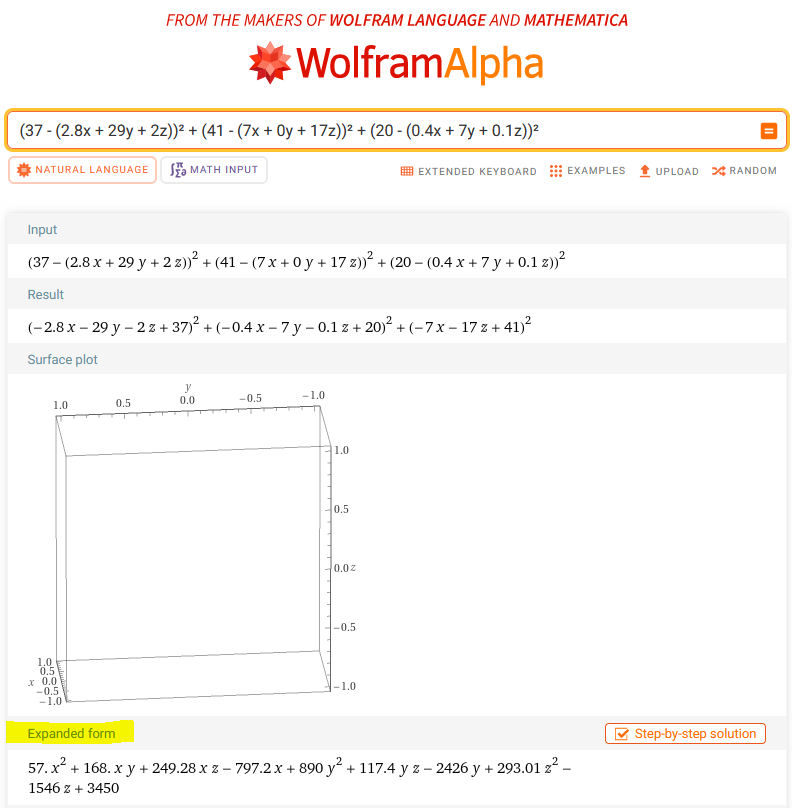

Deze uitdrukking moet je nu omzetten naar een matrixvorm:
De tabel hieronder toont hoe je zo'n uitdrukking terug kan omzetten in een matrix $P$, die je dus nodig hebt voor OSQP:

$$ P = \begin{bmatrix}
  a & d & e \\
  d & b & f \\
  e & f & c \\
\end{bmatrix} $$

Tabel
| Label | de coëfficient van |
|-------|-------------|
| a     |      $x_B^2$ * 2       |
| b     |      $x_K^2$ * 2    |
| c     |      $x_A^2$ * 2     |
| d     |      $x_B x_K $        |
| e     |      $x_B x_A$        |
| f     |      $x_K x_A$      |


Opgelet, de bovenste 3 coëfficiënten kunnen we niet rechtstreeks aflezen: we moeten wat we aflezen met 2 vermenigvuldigen en dat voor de letterwaarde invullen.

In [10]:
from scipy.sparse import csc_matrix
import numpy as np

a = 57 * 2
b = 890 * 2
c = 293 * 2
d = 168.0
e = 249.0
f = 117.0

P = np.array([[a, d, e], [d, b, f], [e, f, c]])
sparse_P = csc_matrix(P)

Er komen nog waarden uit deze uitdrukking (de lineaire stukken). Die horen tot de vector $q$:

In [11]:
q = np.array([-797, -2426, -1546])

**Constraints**

Nu moeten we nog constraints omzetten in de matrix A, en de boven- en ondergrenzen u en l.

Wat zijn zinnige randvoorwaarden voor dit probleem ?

*oplossing*
$$
\begin{align*}
\text{Randvoorwaarden} & \\
&x_B, x_K, x_A \geq 0 \quad \text{(hoeveelheden kunnen niet negatief zijn!)} \\
&2 \leq x_B \leq 3 \qquad \text{(ik eet zeker tussen 200 en 300g broccoli)}  \\
&1 \leq x_K \leq 2 \\
&2 \leq x_A \leq 4 \\
& x_B + x_K + x_A = 7 \qquad \text{(ik eet in totaal 700g)} \\
\end{align*}
$$

In code:

In [12]:
from scipy.sparse import csc_matrix

A_glob = np.ones(3)
A_individ = np.identity(3) # elk gewichtje moet tussen 0 en 1 liggen
A = np.vstack([A_glob, A_individ])
sparse_A = csc_matrix(A)

l = np.array([7.0, 2.0, 1.0, 2.0])
u = np.array([7.0, 3.0, 2.0, 4.0])

Nu kun je OSQP het werk laten doen

In [13]:
import osqp
import numpy as np

# Maak OSQP-probleem
prob = osqp.OSQP()

# Instellen van probleemparameters
prob.setup(P=sparse_P, q=q, A=sparse_A, l=l, u=u, verbose=False) #verbose afzetten voor kortere output
result = prob.solve()

# Uitvoer resultaten
print("Optimale hoeveelheden van ingrediënten:")
print(result.x)


Optimale hoeveelheden van ingrediënten:
[2.9999998  1.40666051 2.5933397 ]


## Aanvulling voor problemen met 2 in plaats van 3 variabelen

Stel dat je niet 3 maar 2 variabelen hebt, dan kan je  onderstaande gebruiken, wat heel gelijkaardig is aan de versie met 3 onbekend. 

De kostfunctie zou eruit kunnen zien als $$ f(x,y) = 120 x^2 + 50 y^2 -30 xy + 6x - 10y + 5 $$

De matrix wordt dan wat simpeler
De tabel hieronder toont hoe je zo'n uitdrukking terug kan omzetten in een matrix $P$, die je dus nodig hebt voor OSQP:

$$ P = \begin{bmatrix}
  a & d  \\
  d & b \\
\end{bmatrix} $$

Tabel
| Label | de coëfficient van |
|-------|-------------|
| a     |      $x^2$  * 2      |
| b     |      $y^2$ * 2    |
| d     |      $x y $       |

# Oplossing Productionfactory

Het doel is om de winst te maximaliseren. Noem $x$ het aantal A-producten, $y$ het aantal B-producten. De winstfunctie is $5x + 8y$. De kostfunctie is het tegengesteld van deze winstfunctie. Er zijn enkel lineaire componenten, dus P is de nulmatrix. 

De beperkingen zijn:
- $2x + y \leq 100$  : beperking op de grondstof X
- $x + 3y \leq 90$ : beperking op de grondstof Y
- $x,y \geq 0$ : geen negatieve oplossingen !

Om deze ongelijkheden te bekomen, verwijs ik naar de techniek met het oplijsten van variabelen en gekende waarden in een tabel. 

In [12]:
import numpy as np
from scipy.sparse import csc_matrix


profit = np.array([5.0, 8.0])
q = -profit

P = np.zeros([2,2])
sparse_P = csc_matrix(P)

Randvoorwaarden in matrix A opstellen

In [13]:
from scipy.sparse import csc_matrix

A_restrict_X = np.array([2, 1])
A_restrict_Y = np.array([1, 3])
A_identity = np.identity(2)

A = np.vstack([A_restrict_X, A_restrict_Y, A_identity])
sparse_A = csc_matrix(A)

u = np.array([100.0, 90.0, np.PINF, np.PINF])
l = np.array([np.NINF, np.NINF, 0.0, 0.0])

In [14]:
import osqp
prob = osqp.OSQP()

# Setup
prob.setup(P=sparse_P, q=q, A=sparse_A, l=l, u=u)

# Solve
result = prob.solve()
print("Oplossing:")
print(result.x)

-----------------------------------------------------------------
           OSQP v0.6.3  -  Operator Splitting QP Solver
              (c) Bartolomeo Stellato,  Goran Banjac
        University of Oxford  -  Stanford University 2021
-----------------------------------------------------------------
problem:  variables n = 2, constraints m = 4
          nnz(P) + nnz(A) = 6
settings: linear system solver = qdldl,
          Oplossing:
[41.98803222 16.00976995]
eps_abs = 1.0e-03, eps_rel = 1.0e-03,
          eps_prim_inf = 1.0e-04, eps_dual_inf = 1.0e-04,
          rho = 1.00e-01 (adaptive),
          sigma = 1.00e-06, alpha = 1.60, max_iter = 4000
          check_termination: on (interval 25),
          scaling: on, scaled_termination: off
          warm start: on, polish: off, time_limit: off

iter   objective    pri res    dua res    rho        time
   1  -4.0139e+01   3.08e-15   8.00e+00   1.00e-01   4.77e-05s
  75  -3.3802e+02   1.73e-02   4.16e-03   1.00e-01   7.24e-05s

status:      

**Oplossing**: de ideale setup bestaat uit het verkopen van ongeveer 42 producten A, en 16 producten B.

In [15]:
41.988 * 2 + 16.009

99.985